In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch import optim 

import numpy as np
import pandas as pd
import time 
import os

from tqdm import tqdm, tqdm_notebook
from PIL import Image
from pathlib import Path

from matplotlib import colors, pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
%matplotlib inline
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{device=}")

device=device(type='cpu')


# Часть 1. Работа с данными (2 балла)
**1.1 Загрузите датасет и приведите в формат, подходящий для тренировки и валидации.**


In [2]:
import os
import pandas as pd
from pathlib import Path

img_train_dir = '/kaggle/input/intersection-flow-5k/Intersection-Flow-5K/images/train'
img_val_dir = '/kaggle/input/intersection-flow-5k/Intersection-Flow-5K/images/val'
img_test_dir = '/kaggle/input/intersection-flow-5k/Intersection-Flow-5K/images/test'
label_val_dir = '/kaggle/input/intersection-flow-5k/Intersection-Flow-5K/labels/val'
label_test_dir = '/kaggle/input/intersection-flow-5k/Intersection-Flow-5K/labels/test'
label_train_dir = '/kaggle/input/intersection-flow-5k/Intersection-Flow-5K/labels/train'

def load_info(img_dir, label_dir, split):
    data = []
    
    for filename in os.listdir(label_dir):
        if not filename.endswith('.txt'):
            continue
        img_name = filename.replace('.txt', '.jpg')
        img_path = os.path.join(img_dir, img_name)
        
        bboxes = []
        class_ids = []
        areas = []
        
        with open(os.path.join(label_dir, filename), 'r') as f:
            lines = f.readlines()
            for line in lines:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                class_id, x_center, y_center, width, height = map(float, parts)
                bboxes.append([x_center, y_center, width, height])
                areas.append(width * height)
                class_ids.append(int(class_id))
        
        num_objects = len(bboxes)
        unique_classes = sorted(set(class_ids)) if class_ids else []
        class_counts = pd.Series(class_ids).value_counts().to_dict() if class_ids else {}

        data.append({
            'image_path': img_path,
            'image_name': img_name,
            'split': split,
            'num_objects': num_objects,
            'class_ids': class_ids,          
            'bboxes': bboxes,
            'areas': areas,
            'unique_classes': unique_classes, 
            'class_counts': class_counts})
            
    return pd.DataFrame(data)


df_val = load_info(img_val_dir, label_val_dir, split='val')
df_test = load_info(img_test_dir, label_test_dir, split='test')
df_train = load_info(img_train_dir, label_train_dir, split='train')

class_names = ['vehicle', 'bus', 'bicycle', 'pedestrian', 'engine', 'truck', 'tricycle', 'obstacle']

print("Train dataset")
print(df_train.head())
print(f"Всего изображений в train: {len(df_train)}")
print(f"Среднее число объектов на изображении: {df_train['num_objects'].mean():.2f}")
print(f"Имена классов: {class_names}")

Train dataset
                                          image_path  \
0  /kaggle/input/intersection-flow-5k/Intersectio...   
1  /kaggle/input/intersection-flow-5k/Intersectio...   
2  /kaggle/input/intersection-flow-5k/Intersectio...   
3  /kaggle/input/intersection-flow-5k/Intersectio...   
4  /kaggle/input/intersection-flow-5k/Intersectio...   

                 image_name  split  num_objects  \
0  1697256444.757439137.jpg  train           31   
1              20219354.jpg  train           33   
2  1662381421.804147005.jpg  train           71   
3  1697263884.328517437.jpg  train           30   
4  1662380328.921214819.jpg  train           93   

                                           class_ids  \
0  [0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...   
1  [0, 0, 0, 0, 3, 3, 3, 3, 3, 3, 3, 2, 2, 3, 0, ...   
2  [0, 0, 0, 0, 0, 0, 0, 0, 5, 7, 7, 7, 7, 3, 7, ...   
3  [0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...   
4  [7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, ...   

     

**1.2 Выполните анализ данных - оцените распределение объектов по классам, распределение числа объектов на изображении, масштаб объектов и размер изображений.**

Анализ данных будем выполнять для тренировочного датасета.

Посмотрим на распределение числа объектов на изображениях.

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


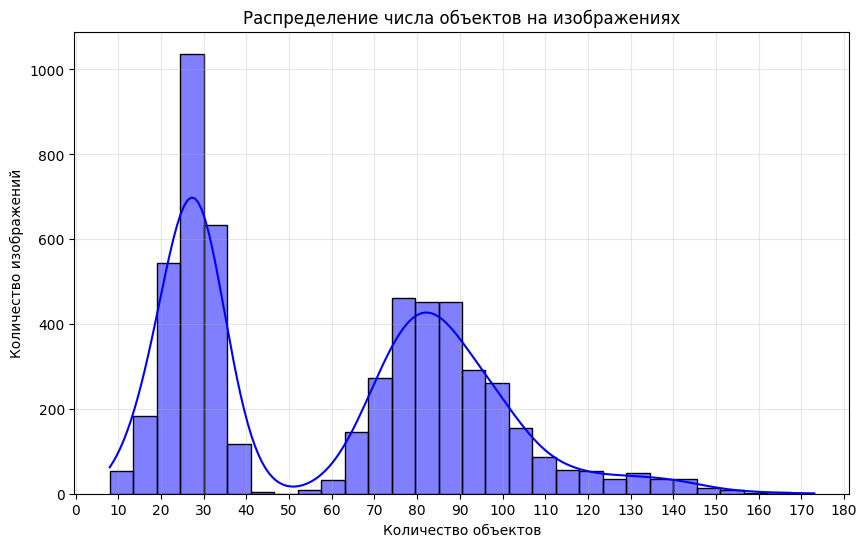

In [3]:
plt.figure(figsize=(10, 6))
sns.histplot(df_train['num_objects'], bins=30, kde=True, color='blue')
plt.title('Распределение числа объектов на изображениях')
plt.xlabel('Количество объектов')
plt.xticks(range(0, int(df_train['num_objects'].max()) + 10, 10))
plt.ylabel('Количество изображений')
plt.grid(True, alpha=0.3)
plt.show()

По графику видно, что наиблее часто на изображении от 20 до 35 объектов или от 75 до 100.

Посмотрим, сколько объектов каждого класса есть в тренировочном датасете.

0    190417
1      2816
2     23396
3     19005
4       642
5      7749
6      1610
7     82190
Name: count, dtype: int64


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


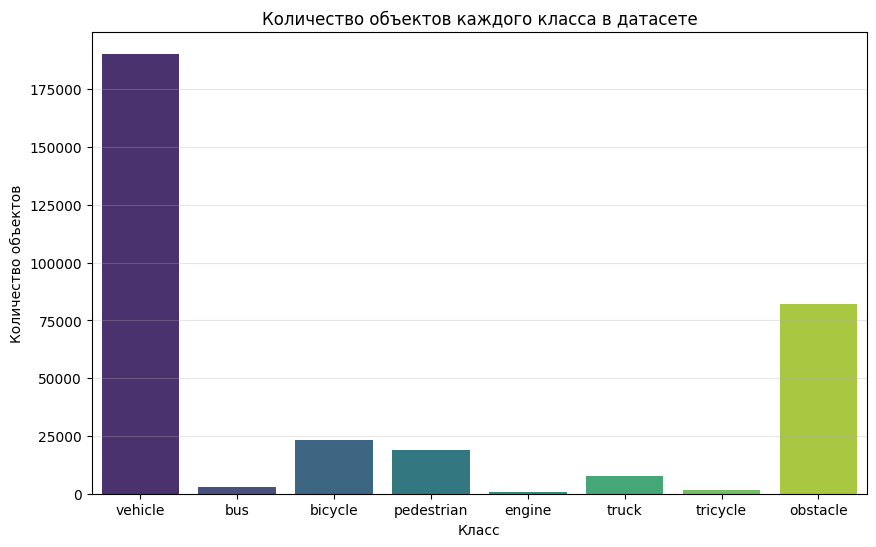

In [4]:
import pandas as pd

class_ids_all = [cls for sublist in df_train['class_ids'] for cls in sublist]

class_freq = pd.Series(class_ids_all).value_counts().sort_index()
print(class_freq)
plt.figure(figsize=(10, 6))
sns.barplot(x=class_names, y=class_freq, palette='viridis')
plt.title('Количество объектов каждого класса в датасете')
plt.xlabel('Класс')
plt.ylabel('Количество объектов')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

Больше всего объектов vehicle (я так понимаю, это просто машины), еще довольно много препятствий. Не очень много, но все же есть велосипедисты и пешеходы. Остальные классы встречаются довольно редко. По классам датасет сильно несбалансированный.

Посмотрим на распределение классов объектов на изображениях.

{0: 5483, 1: 2014, 2: 4534, 3: 4113, 4: 577, 5: 3347, 6: 1446, 7: 2910}


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


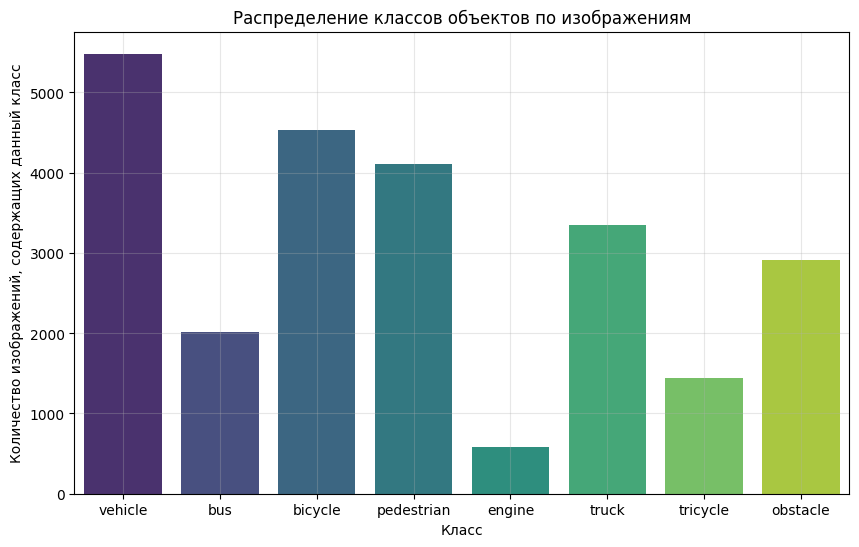

In [5]:
class_num  = {}
for idx, row in df_train.iterrows():
    for cls in row['unique_classes']:
        class_num[cls] = class_num.get(cls, 0) + 1

plt.figure(figsize=(10, 6))
class_num = dict(sorted(class_num.items()))
print(class_num)
classes = list(class_num.keys())
counts = list(class_num.values())
sns.barplot(x=class_names, y=counts, palette='viridis')
plt.title('Распределение классов объектов по изображениям')
plt.xlabel('Класс')
plt.ylabel('Количество изображений, содержащих данный класс')
plt.grid(True, alpha=0.3)
plt.show()

Как и ожидалось из пункта выше, машины встречаются на бОльшем количестве изображений, чем все остальные классы. Так же на многих картинках есть велосипеды и пешеходы. Не смотя на то что в целом объектов obstacle больше в датасете, чем переходов и велосипедистов, они встречаются на меньшем количестве изображений, видимо потому что они в большем количестве расположены на одном изображении.

**1.3 Напишите код для визуализации разметки и предикшенов. Визуализируйте разметку для одного изображения из каждого класса.**

In [6]:
def load_yolo_predictions(label_dir, image_paths):
    predictions = {}
    for img_path in image_paths:
        base_name = os.path.basename(img_path)
        txt_name = os.path.splitext(base_name)[0] + '.txt'
        txt_path = os.path.join(label_dir, txt_name)

        preds = []
        with open(txt_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    class_id, xc, yc, w, h = map(float, parts)
                    preds.append([class_id, xc, yc, w, h])
                    
        predictions[img_path] = preds
    return predictions

In [7]:
colors = np.random.randint(0, 255, size=(8, 3), dtype=np.uint8)
colors = [tuple(c / 255.0) for c in colors]

In [9]:
def visualize_predictions(image_path, predictions, colors, class_names=None, n_classes=8, save_path=None):
    try:
        img = Image.open(image_path).convert("RGB")
    except Exception as e:
        print(f"Не удалось загрузить изображение: {image_path} — {e}")
        return

    img_array = np.array(img)
    h, w = img_array.shape[:2]
    #np.random.seed(42)
    #colors = np.random.randint(0, 255, size=(8, 3), dtype=np.uint8)
    #colors = [tuple(c / 255.0) for c in colors]

    fig, ax = plt.subplots(1, figsize=(12, 8))
    ax.imshow(img_array)
    ax.axis('off')

    for pred in predictions:
        class_id = int(pred[0])
        x_center_norm = float(pred[1])
        y_center_norm = float(pred[2])
        width_norm = float(pred[3])
        height_norm = float(pred[4])

        x_center = x_center_norm * w
        y_center = y_center_norm * h
        bbox_width = width_norm * w
        bbox_height = height_norm * h

        x1 = x_center - bbox_width / 2
        y1 = y_center - bbox_height / 2

        color = colors[class_id % n_classes]

        rect = patches.Rectangle(
            (x1, y1),
            bbox_width,
            bbox_height,
            linewidth=2,
            edgecolor=color,
            facecolor='none'
        )
        ax.add_patch(rect)

        label = class_names.get(class_id, f"Class {class_id}") if class_names else f"Class {class_id}"
        ax.text(
            x1, y1 - 5,
            label,
            color=color,
            fontsize=10,
            weight='bold',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=0.5)
        )

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight', pad_inches=0)

    plt.show()



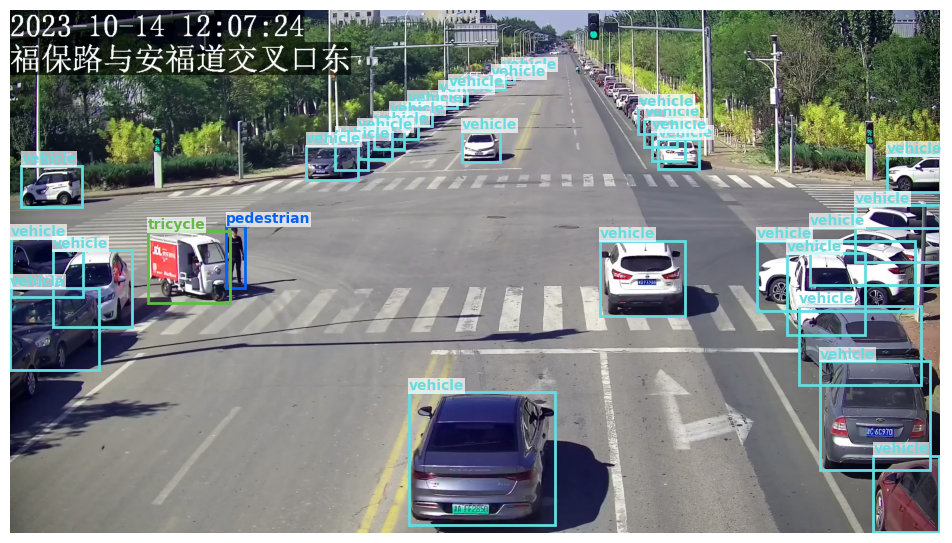

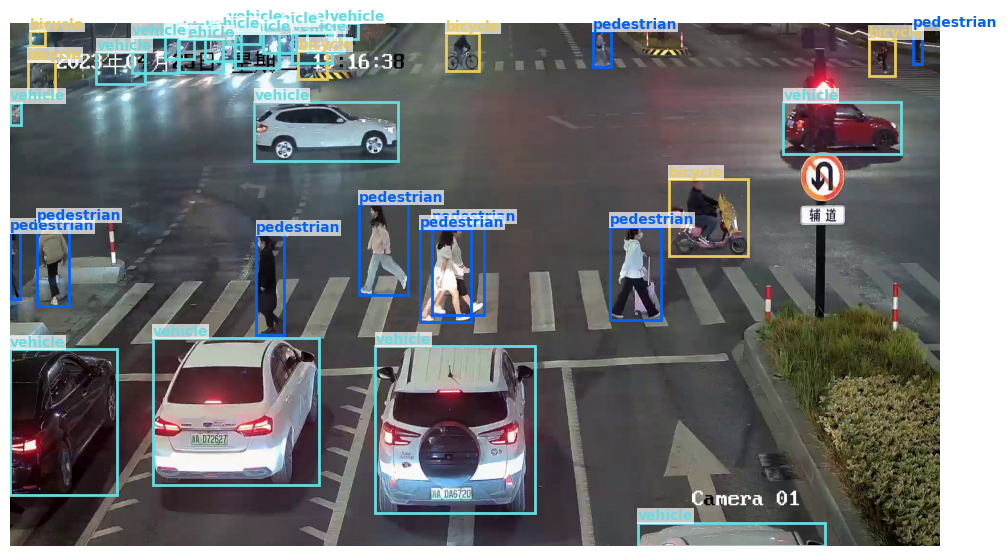

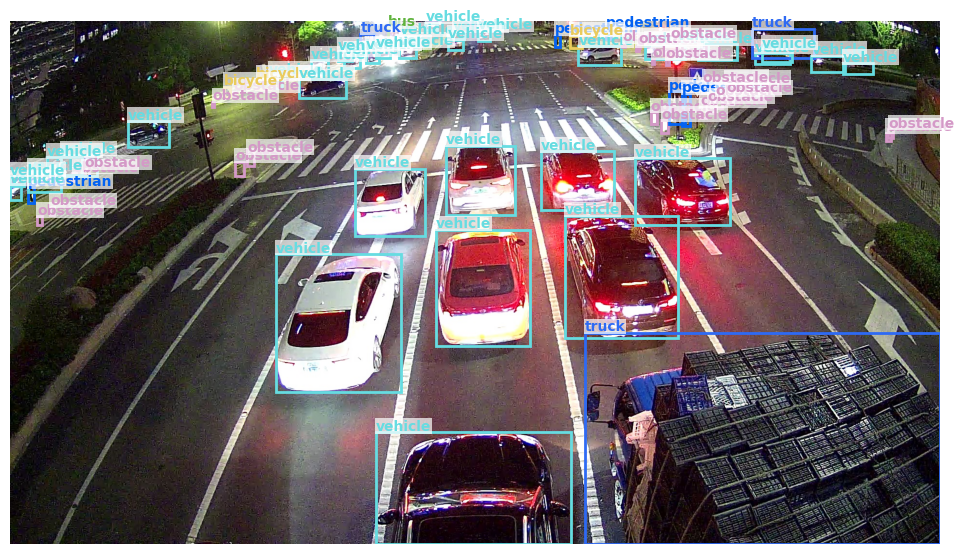

In [11]:
label_dir = '/kaggle/input/intersection-flow-5k/Intersection-Flow-5K/labels/train'

image_paths = df_train['image_path'].tolist()
preds_dict = load_yolo_predictions(label_dir, image_paths)

class_dict = {0: 'vehicle', 1: 'bus', 2: 'bicycle', 3: 'pedestrian', 4: 'engine', 5: 'truck', 6: 'tricycle', 7: 'obstacle'}

for i in range(min(3, len(image_paths))):
    img_path = image_paths[i]
    preds = preds_dict.get(img_path, [])

    save_file = f"image_bbox_{i+1}.jpg"
    visualize_predictions(image_path=img_path, predictions=preds, colors=colors, class_names=class_dict, n_classes=8, save_path=save_file)